In [ ]:
%pip install mrmr-selection

In [2]:
# Import neccessary libraries
import itertools

import pandas as pd
import numpy as np

# For graph plot
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

# For feature scaling and selection
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, MaxAbsScaler
from sklearn.feature_selection import mutual_info_regression, SequentialFeatureSelector
from sklearn.svm import SVR
from mrmr import mrmr_regression

# For DLNM model
from statsmodels.gam.gam_cross_validation.cross_validators import KFold
import statsmodels.api as sm
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.gam.gam_cross_validation.gam_cross_validation import MultivariateGAMCVPath
from statsmodels.genmod.families.family import Tweedie
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from pydlnm.utils import logknots
from dlnm import crossbasis, plot_crosspred, cb_pen


In [3]:
# Function for constructing the CrossBasis matrix
def crossbasis_construct(dataframe, col_lst, max_lag, setting_lst): 
    # setting_lst include the values for the degree and degree of freedom (df) for both exposure and lag dimension in order
    
    # Initlialize the list to place cross basis matrices
    cb_list = []

    # Construct cross basis for each exposure variables
    for col in col_lst:
        knots_var = np.quantile(dataframe[col].dropna(), [0.1, 0.75, 0.9])
        lag_knots = logknots([0, max_lag], nk=setting_lst[3])

        tmp_cb = CrossBasis(dataframe[col].values, lag=max_lag, 
                                argvar={"fun": "bs", "degree": setting_lst[0], "df": setting_lst[1]}, 
                                arglag={"fun": "bs", "degree": setting_lst[2], "df": setting_lst[3]})
        cb_list.append(tmp_cb)

    X_exposure = np.concat(cb_list, axis=1)

    # Construct the DataFrame object for later model construction 
    model_data = np.concat([dataframe.to_numpy(), X_exposure], axis=1)
    model_data = pd.DataFrame(model_data)

    # Rename the columns of the mode_data DataFrame 
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(tmp_cb.shape[1])]
    model_data.columns = [n for n in dataframe.columns if n!="From"] + exp_name_list

    # Fill in 0 for the missing value(s)
    model_data[exp_name_list] = model_data[exp_name_list].fillna(0)

    # Return the variables that need to be used 
    return model_data, exp_name_list, cb_list

In [4]:
# Function for constructing the smoothers 
def smoothers_construct(dataframe, bs_dict, cs_dict):
    # bs_dict and cs_dict contains the name, degree and df for the spline function constructions needed 
    
    bs_list = []
    # Use B spline for 'Year'
    for i in range(len(bs_dict["name"])):
        tmp_bs = UnivariateBSplines(dataframe[bs_dict["name"][i]], df=bs_dict["df"][i], degree=bs_dict["degree"][i], include_intercept=False, variable_name=bs_dict["name"][i])
        bs_list.append(tmp_bs)
        
    
    # Use Cubic Cyclic Spline for 'Week'
    cs = UnivariateCubicCyclicSplines(dataframe[cs_dict["name"]], df=cs_dict["df"], constraints="center", variable_name=cs_dict["name"])

    # Group the two spline functions together to form a single smoother variable
    sm_weights = bs_list + [cs]
    X_smooth = dataframe[bs_dict["name"]+[cs_dict["name"]]]
    smoothers = GenericSmoothers(X_smooth, sm_weights)

    # Return the smoother variable
    return smoothers

In [5]:
# Function for constructing GAM model with Negative Binomial family 
def NB_GAM_model(dataframe, tar_var, exp_names, smoothers, a): 
    # Initializa the formula
    formula = f"{tar_var} ~ {exp_names} + pandemic_flag"

    # Build and fit the model
    NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=a, family=sm.families.NegativeBinomial(alpha=0.5))
    result = NegativeBinomial_gam_model.fit()
    # result = NegativeBinomial_gam_model.fit_regularized(method="l1_slsqp", alpha=1.0)
        # no penalization for Negative Binomial

    # Return the model and the result 
    return NegativeBinomial_gam_model, result

In [6]:
# Function for 
def pred_cal(result, dataframe, cb_lst, mete_lst, i):
    n_cb_cols = cb_lst[i].shape[1]
    start_idx = 0
    end_idx = start_idx+n_cb_cols
    cb_coef = result.params.values[start_idx:end_idx]
    cb_vcov = result.cov_params().iloc[start_idx:end_idx, start_idx:end_idx]
    at = np.linspace(dataframe[mete_lst[i]].min(), dataframe[mete_lst[i]].max(), 100)
    cen = dataframe[mete_lst[i]].median()
    pred = crosspred(basis=cb_lst[i], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    
    print(f"{mete_lst[i]} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")

    return pred

In [7]:
# Function for plotting the 3D graph 
def graph_3Dplot(pred, exp):
    fig = plot_crosspred(pred, ptype="3d")

    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel(exp, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Residual Risk (RR)", labelpad=10)
    ax.set_yticks(np.linspace(0, 4, pred.matRRfit.shape[1]))

    plt.tight_layout()
    plt.show()

In [8]:
# Function for plotting the exposure-response slice plot
def graph_expresponseplot(pred, exp):
    fig = plot_crosspred(pred, ptype="overall")
    cen = df[exp].median()

    ax = fig.gca()

    ax.axvline(x=cen, color='black', linestyle=':', linewidth=1.2, label=f'Centering Temp ({cen:.1f}°C)')
    ax.set_title('Overall Cumulative Exposure-Response Association', fontsize=14, pad=15)
    ax.set_xlabel(exp, fontsize=12)
    ax.legend(loc="best", frameon=True)

    plt.show()

In [9]:
# Function for plotting the lag-response slice plot
def graph_lagresponseplot(pred, target_var):
    fig = plot_crosspred(
        pred, 
        ptype="slices", 
        var=target_var
    )

    ax = fig.gca()

    ax.set_title(f"Lag-Response Curve at {target_var}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color='gray', linestyle='--', alpha=0.7) # Add baseline at RR=1
    
    plt.show()

In [10]:
# Function for all the three plots at the same time 
def graph_plot(pred, exp, val):
    graph_3Dplot(pred, exp)
    graph_expresponseplot(pred, exp)
    graph_lagresponseplot(pred, val)

In [11]:
def alpha_byAIC(dataframe, tar_var, exp_names, smoothers, alpha):
    best_a = 0
    best_aic = np.inf

    for a1, a2, a3 in itertools.product(alpha, alpha, alpha):
        model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [a1, a2, a3])
        print(f"alpha {[a1, a2, a3]} with AIC value {result.aic}")
        if result.aic < best_aic:
            best_aic = result.aic
            best_a = [a1, a2, a3]

    return best_a

In [12]:
def alpha_byGCV(dataframe, tar_var, exp_names, smoothers):
    model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [100, 500, 500])
    best_a = model.select_penweight(criterion="gcv")
    return best_a[0]

In [13]:
def cb_setting_performance(dataframe, exp_col, setting_options):
    best_setting_idx = 0
    performance = []
    for set in setting_options:
        model_data, exp_name_list, cb_list = crossbasis_construct(dataframe, exp_col, 4, set)
        smoothers = smoothers_construct(model_data, {"name": ["time", "stringency_index"], "degree": [3, 3], "df": [6, 4]}, {"name": "Week", "df": 4})
        initial_alpha = [1.0, 1.0, 1.0]
        model, result = NB_GAM_model(model_data, "H1",  " + ".join(exp_name_list), smoothers, initial_alpha)
        print(f"AIC value for the settings {set}: {result.aic}")
        performance.append([result.aic, result.deviance, result.null_deviance, result.df_resid, result.df_model])

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_setting_idx][0]:
            best_setting_idx = i

    return setting_options[best_setting_idx]


In [14]:
# Function for feature scaling (uses standardlization)
def feature_scaling():
    df[mete_col] = StandardScaler().fit_transform(df[mete_col])
    df["Year"] = df["Year"] - df["Year"].mean()
  

In [15]:
def feature_selection_MI(dataframe, exp_col, outcome_col):
    X = dataframe[exp_col]
    Y = dataframe[outcome_col]
    
    # Calculate mutual information for regression
    mi_scores = mutual_info_regression(X, Y)
    
    # Display scores
    mi_df = pd.DataFrame({'Feature': [col for col in X], 'MI_Score': mi_scores})
    selected_features = mi_df.loc[mi_df["MI_Score"]>=0, "Feature"].to_list()

    return mi_df.sort_values(by='MI_Score', ascending=False), selected_features

In [16]:
def feature_selection_MRMR(dataframe, exp_col, outcome_col):
    selected_features = mrmr_regression(X=dataframe[exp_col], y=dataframe[outcome_col], K=5)
    print("Selected Features:", selected_features)
            
    return selected_features 

---

In [17]:
# Import data and basic settings
df = pd.read_csv("data.csv")

df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB"]

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]

df["From"] = pd.to_datetime(df["From"])


In [18]:

url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"

df_owid = pd.read_csv(url)

country_code = "HKG"
df_country = df_owid[df_owid["iso_code"] == country_code].copy()

df_country["date"] = pd.to_datetime(df_country["date"])

df_stringency = df_country[["date", "stringency_index"]].copy()


In [19]:
df = pd.merge(df, df_stringency, left_on="From", right_on="date", how="left")
df["stringency_index"] = df["stringency_index"].fillna(0.0)

covid_index = df[((df["From"] >= "2020-01-03") & (df["From"] <= "2023-03-01"))].index
df.loc[covid_index, "pandemic_flag"] = 1
df["pandemic_flag"].fillna(0, inplace=True)

df.drop(columns=["date", "From"], inplace=True)

df["time"] = np.arange(1, len(df)+1)

In [20]:
df.head()

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,stringency_index,pandemic_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,5


In [21]:
# Feature scaling and selection
np.random.seed(42)

feature_scaling()
feature_selection_MI(df, mete_col, "H1")
mete_col = feature_selection_MRMR(df, mete_col, "H1")

100%|██████████| 5/5 [00:04<00:00,  1.21it/s]

Selected Features: ['UV', 'RH', 'WS', 'temp', 'SR']


In [22]:
initial_alpha = [1.0, 1.0, 1.0]
initial_cb_setting = [2, 5, 3, 5]

In [23]:
setting_options = [
    [2, 5, 3, 5], 
    [2, 4, 3, 5], 
    [2, 3, 3, 5], 
    [2, 5, 2, 4],
    [2, 4, 2, 4]
]

best_cb_setting = cb_setting_performance(df, mete_col, setting_options)
print(f"The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: \n{best_cb_setting}")

AIC value for the settings [2, 5, 3, 5]: 10430.134940163642
AIC value for the settings [2, 4, 3, 5]: 10336.667318951264
AIC value for the settings [2, 3, 3, 5]: 10389.418826852505
AIC value for the settings [2, 5, 2, 4]: 10456.958240864227
AIC value for the settings [2, 4, 2, 4]: 10249.574031116148
The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: 
[2, 4, 2, 4]


In [24]:
model_data, exp_name_list, cb_list = crossbasis_construct(df, mete_col, 4, best_cb_setting)

display(model_data.head())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,...,SR_basis_6,SR_basis_7,SR_basis_8,SR_basis_9,SR_basis_10,SR_basis_11,SR_basis_12,SR_basis_13,SR_basis_14,SR_basis_15
0,-12.172386,36.0,-0.159389,0.952562,-0.263359,1.074896,-0.768413,0.666793,-1.504003,0.882471,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
1,-12.172386,37.0,-0.357210,0.662780,0.737677,-0.882043,-1.081663,0.767450,0.235168,0.086233,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
2,-12.172386,38.0,-1.035453,0.602825,0.502139,0.522550,-0.249079,0.666793,1.863914,0.882471,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
3,-12.172386,39.0,-1.374575,0.502901,0.737677,-0.582144,0.006467,0.675181,1.753491,0.086233,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
4,-12.172386,40.0,-1.205014,0.512893,0.384370,-0.462563,-0.010020,0.532584,-0.013285,0.086233,...,0.633737,0.410517,0.000009,0.180192,0.180192,0.589274,0.0,0.000148,0.000148,0.097182


In [ ]:
train_end = int(model_data.shape[0] * 0.6)
validation_end = int(model_data.shape[0] * 0.8)

train_data = model_data.iloc[:train_end]
validation_data = model_data.iloc[train_end:validation_end]
test_data = model_data.iloc[validation_end:]


In [ ]:
smoothers = smoothers_construct(model_data, {"name": ["time", "stringency_index"], "degree": [3, 3], "df": [6, 4]}, {"name": "Week", "df": 4})


In [26]:
alpha_choice = [1.0, 10.0, 50.0, 100.0]
best_a_aic = alpha_byAIC(model_data, "H1", " + ".join(exp_name_list), smoothers, alpha_choice)

print(f"alpha {best_a_aic} is the best tested with AIC")

alpha [1.0, 1.0, 1.0] with AIC value 10249.574031116148
alpha [1.0, 1.0, 10.0] with AIC value 10249.259185021216
alpha [1.0, 1.0, 50.0] with AIC value 10247.995670267654
alpha [1.0, 1.0, 100.0] with AIC value 10246.694363325327
alpha [1.0, 10.0, 1.0] with AIC value 10249.61024069776
alpha [1.0, 10.0, 10.0] with AIC value 10249.295002676457
alpha [1.0, 10.0, 50.0] with AIC value 10248.029826181873
alpha [1.0, 10.0, 100.0] with AIC value 10246.726594412683
alpha [1.0, 50.0, 1.0] with AIC value 10249.811425796692
alpha [1.0, 50.0, 10.0] with AIC value 10249.494812970132
alpha [1.0, 50.0, 50.0] with AIC value 10248.223818612625
alpha [1.0, 50.0, 100.0] with AIC value 10246.913857510155
alpha [1.0, 100.0, 1.0] with AIC value 10250.105425368532
alpha [1.0, 100.0, 10.0] with AIC value 10249.787711816885
alpha [1.0, 100.0, 50.0] with AIC value 10248.512084524928
alpha [1.0, 100.0, 100.0] with AIC value 10247.196790200705
alpha [10.0, 1.0, 1.0] with AIC value 10249.574095631968
alpha [10.0, 1.0

In [32]:
best_a_gcv = alpha_byGCV(model_data, "H1", " + ".join(exp_name_list), smoothers)

print(f"alpha {best_a_gcv} is the best tested with GCV")


alpha [1.22444931e+05 1.05933878e-35 5.52388934e+48] is the best tested with GCV


In [56]:
model, result = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_aic)
print(result.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1160.19
Model Family:        NegativeBinomial   Df Model:                        91.81
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -5030.5
Date:                Thu, 12 Nov 2026   Deviance:                       3904.1
Time:                        21:07:06   Pearson chi2:                 1.82e+05
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.9977
Covariance Type:            nonrobust                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.7179    

In [47]:
for s in smoothers.smoothers:
    if getattr(s, "der_basis", None) is None:
        s.der_basis = np.zeros_like(s.basis)
    if getattr(s, "der2_basis", None) is None:
        s.der2_basis = np.zeros_like(s.basis)

best_a_kfold = model.select_penweight_kfold()

In [57]:
print(f"AIC: {result.aic}")
print(f"BIC: {result.bic}")
print(f"Deviance: {result.deviance}")
print(f"Pearson Chi2: {result.pearson_chi2}")
print(f"Scale/Dispersion: {result.scale}")
print(f"Effective degree of freedom: \n{result.edf}")
print(f"Total EDF: {result.edf.sum()}")

AIC: 10246.694363325327
BIC: 10723.140624140931
Deviance: 3904.109684682604
Pearson Chi2: 182186.82748178844
Scale/Dispersion: 1.0
Effective degree of freedom: 
[0.35289638 1.09764971 1.08149492 0.49626479 0.8186816  1.21514452
 1.51414497 0.99783116 1.52939443 1.13949652 1.3152393  0.67610543
 1.14188392 0.91364541 0.75152938 1.09317769 0.71863164 1.23316558
 1.10921258 0.728064   0.84129624 0.92501729 0.70293852 0.73163301
 0.89874737 1.17327235 0.78518122 0.88611604 1.01150814 1.19122795
 1.18468364 1.10165826 1.12820176 1.04794    1.17038552 1.33950614
 1.21163365 1.23305716 1.17024778 1.24598289 1.19378779 0.84195751
 0.90428482 1.05393277 1.0793493  1.17924236 1.23506824 0.8521332
 0.79394649 1.0229612  1.07002548 0.80383968 1.01747442 1.03573159
 1.23767318 1.06777912 0.90096161 0.75319438 1.07014975 0.681926
 0.66975612 1.06513713 1.09535765 0.9939913  0.76496155 0.87739594
 0.83986017 0.95915413 0.76468646 0.93640569 0.54979571 0.59440249
 0.62265793 0.93758358 0.53273037 1.11

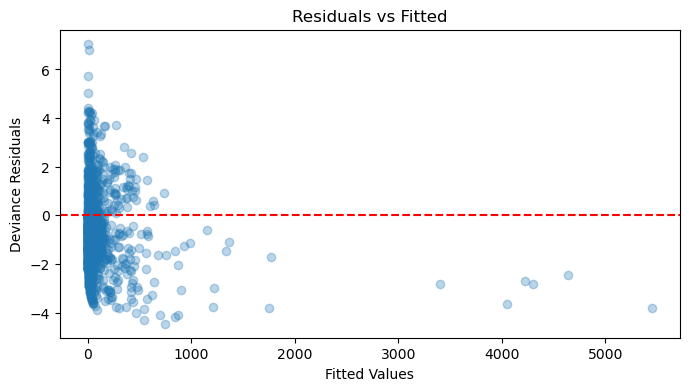

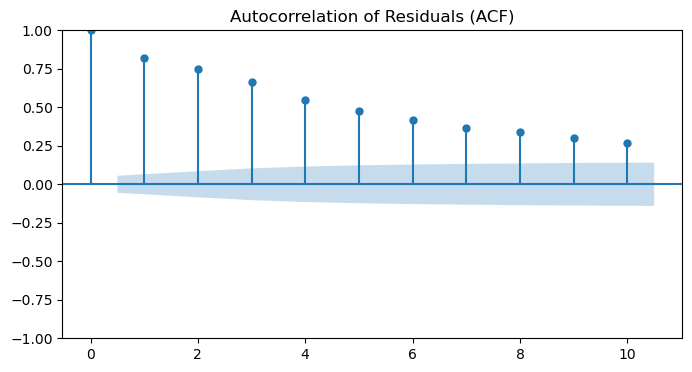

In [58]:
# Extract deviance residuals
residuals = result.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [59]:
# Find the index of the highest fitted value
extreme_idx = result.fittedvalues.idxmax()

print(f"Index of extreme row: {extreme_idx}")
print(f"Actual Outcome Value: {model_data.loc[extreme_idx, "H1"]}")
print(f"Fitted Value: {result.fittedvalues[extreme_idx]}")
print(model_data.loc[extreme_idx])

Index of extreme row: 285
Actual Outcome Value: 54.0
Fitted Value: 5446.8077670070425
Year          -6.172386
Week           8.000000
temprange      1.140577
temp          -1.555546
RH            -0.204474
                 ...   
SR_basis_11    0.000000
SR_basis_12    0.000000
SR_basis_13    0.000000
SR_basis_14    0.000000
SR_basis_15    0.000000
Name: 285, Length: 97, dtype: float64


UV RR range: 0.120 to 291.501


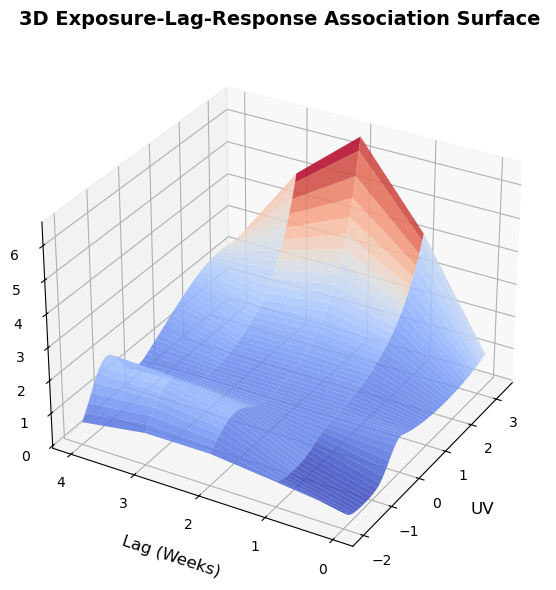

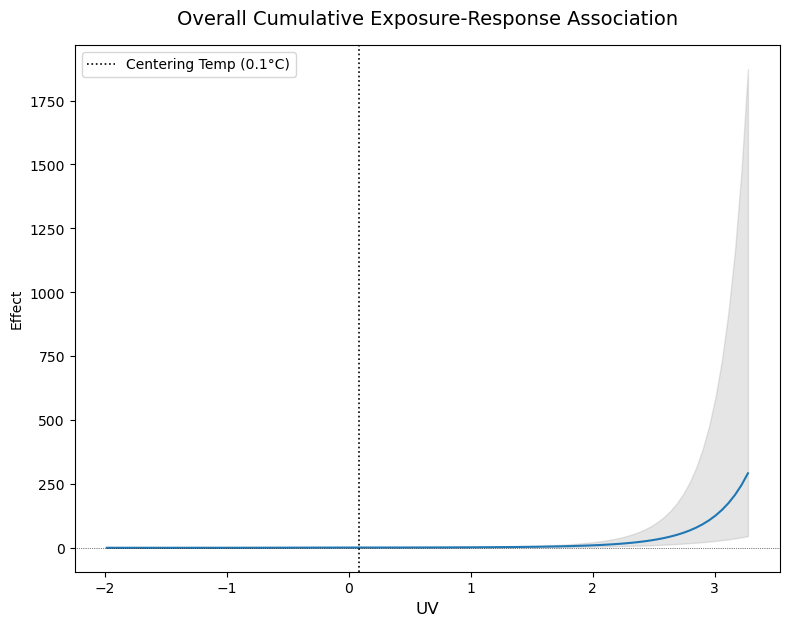

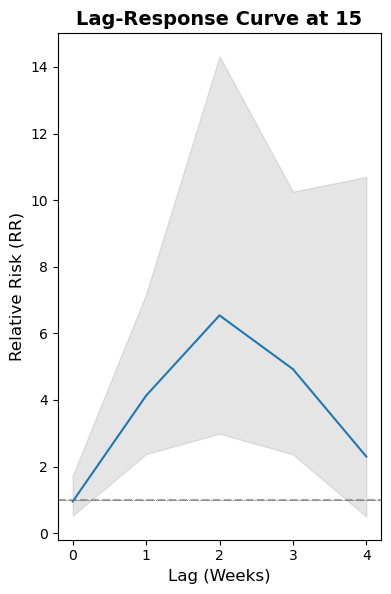

In [60]:
pred = pred_cal(result, model_data, cb_list, mete_col, 0)
graph_plot(pred, mete_col[0], 15)

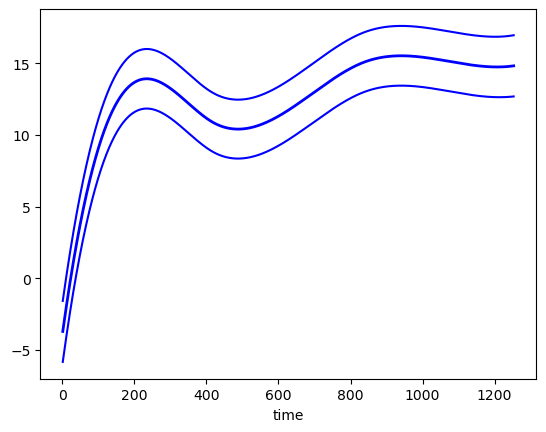

In [38]:
result.plot_partial(0)
plt.show()